In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import SGD

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# --- 1. Load and Prepare Data ---

filepath = '/content/drive/MyDrive/MScDS&AI/ANN/student-mat.csv'

# 1. Read the CSV file (assuming delimiter is ';')
# try...except block removed as requested
df = pd.read_csv(filepath, sep=';')


In [9]:

print("--- 1. Initial Data Info ---")
# 2. Display columns and type
df.info()
print("\n")


df['High_G3'] = np.where(df['G3'] > 10, 'High', 'Moderate')

# 4. Print the distribution of High_G3
print("--- 2. Distribution of new 'High_G3' column ---")
print(df['High_G3'].value_counts())
print("\n")

# 5. Remove G3 column
df = df.drop('G3', axis=1)

# 6. Prepare X (all features except High_G3) and y (High_G3)
y_data = df['High_G3']
X_data = df.drop('High_G3', axis=1)

# 7. Convert categorical features to one-hot encoding
X_processed = pd.get_dummies(X_data, drop_first=True)

# Convert y to numerical (0 for Moderate, 1 for High)
label_encoder = LabelEncoder()
y_processed = label_encoder.fit_transform(y_data)

# 8. StandardScaler features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_processed)


--- 1. Initial Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-n

In [10]:

# 9. Perform train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_processed, test_size=0.2, random_state=42, stratify=y_processed
)

input_dim = X_train.shape[1]

# --- 10. i. Batch Gradient Descent ---
print("--- 3. Training MLP with Batch Gradient Descent ---")


--- 3. Training MLP with Batch Gradient Descent ---


In [11]:

# Create the model
model_batch = Sequential()
model_batch.add(Dense(64, activation='relu', input_dim=input_dim))
model_batch.add(Dense(32, activation='relu'))
model_batch.add(Dense(16, activation='relu'))
model_batch.add(Dense(1, activation='sigmoid'))

# Compile the model
optimizer_batch = SGD(learning_rate=0.01)
model_batch.compile(optimizer=optimizer_batch,
              loss='mean_squared_error',
              metrics=['accuracy'])

# Batch GD: batch_size is the entire training set
batch_size_full = X_train.shape[0]

history_batch = model_batch.fit(
    X_train, y_train,
    epochs=50,
    batch_size=batch_size_full,
    validation_data=(X_test, y_test),
    verbose=1
)
print("\nBatch GD Training Complete.\n")


Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.4842 - loss: 0.2870 - val_accuracy: 0.4177 - val_loss: 0.2922
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.4842 - loss: 0.2865 - val_accuracy: 0.4177 - val_loss: 0.2918
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.4873 - loss: 0.2860 - val_accuracy: 0.4177 - val_loss: 0.2913
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.4873 - loss: 0.2855 - val_accuracy: 0.4177 - val_loss: 0.2909
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.4873 - loss: 0.2850 - val_accuracy: 0.4177 - val_loss: 0.2904
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.4873 - loss: 0.2845 - val_accuracy: 0.4177 - val_loss: 0.2900
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.4873 - loss: 0.2840 - val_accuracy: 0.4177 - val_loss: 0.2896
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.4873 - loss: 0.2835 - val_accuracy: 0.4177 - val_loss: 0.2891
Epoch 

In [12]:

# --- 10. ii. Stochastic Gradient Descent ---
print("--- 4. Training MLP with Stochastic Gradient Descent ---")

# Create the model
model_sgd = Sequential()
model_sgd.add(Dense(64, activation='relu', input_dim=input_dim))
model_sgd.add(Dense(32, activation='relu'))
model_sgd.add(Dense(16, activation='relu'))
model_sgd.add(Dense(1, activation='sigmoid'))

# Compile the model
optimizer_sgd = SGD(learning_rate=0.01)
model_sgd.compile(optimizer=optimizer_sgd,
              loss='mean_squared_error',
              metrics=['accuracy'])

# Stochastic GD: batch_size = 1
history_sgd = model_sgd.fit(
    X_train, y_train,
    epochs=50,
    batch_size=1,
    validation_data=(X_test, y_test),
    verbose=1
    # Verbose=1 shows progress bar, which can be slow for SGD.
    # Set to verbose=2 for one line per epoch, or 0 for silent.
)
print("\nSGD Training Complete.\n")


--- 4. Training MLP with Stochastic Gradient Descent ---
Epoch 1/50
316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6114 - loss: 0.2405 - val_accuracy: 0.7089 - val_loss: 0.1989
Epoch 2/50
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8362 - loss: 0.1531 - val_accuracy: 0.8354 - val_loss: 0.1421
Epoch 3/50
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8902 - loss: 0.0966 - val_accuracy: 0.8481 - val_loss: 0.1152
Epoch 4/50
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9355 - loss: 0.0678 - val_accuracy: 0.8481 - val_loss: 0.1020
Epoch 5/50
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9600 - loss: 0.0506 - val_accuracy: 0.8987 - val_loss: 0.0936
Epoch 6/50
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9720 - loss: 0.0390 - val_accuracy: 0.8987 - val_loss: 0.0892
Epoch 7/50
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9727 - loss: 0.0317 - val_accuracy: 0.8987 - val_loss: 0.0868
Epoch 8/50
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/

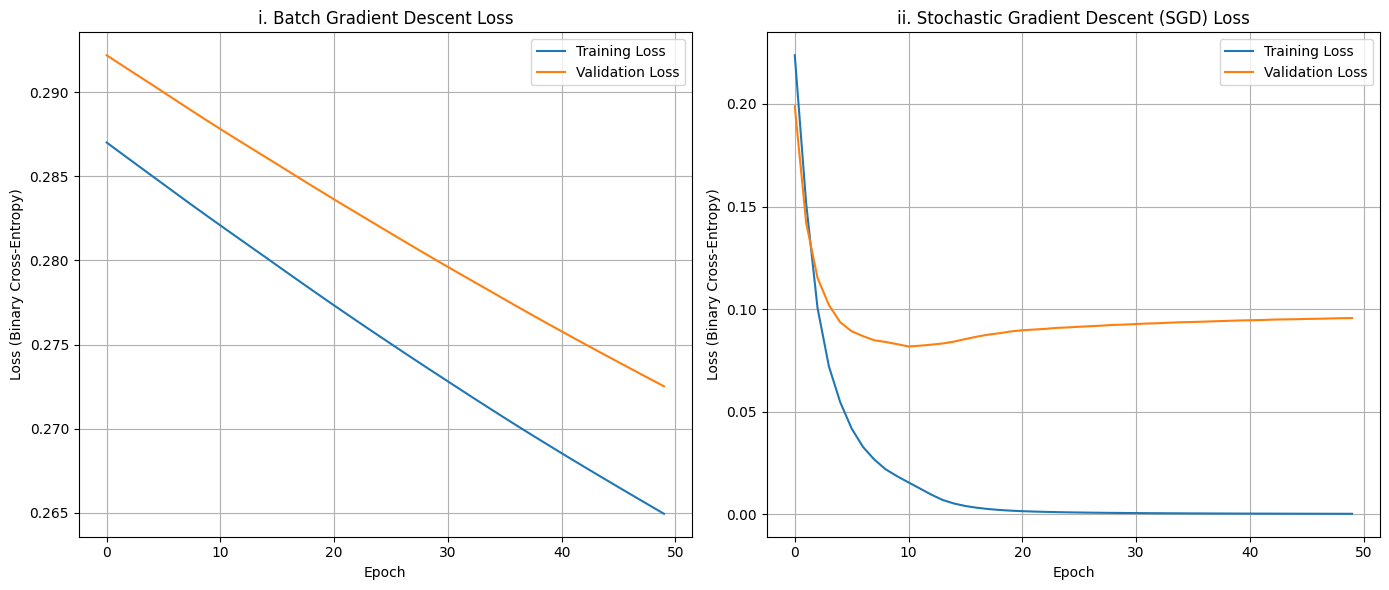

--- 5. Evaluation of Batch GD Model ---
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Accuracy: 0.4304

Classification Report:
              precision    recall  f1-score   support

        High       0.48      0.74      0.58        42
    Moderate       0.21      0.08      0.12        37

    accuracy                           0.43        79
   macro avg       0.35      0.41      0.35        79
weighted avg       0.35      0.43      0.36        79

Confusion Matrix:
[[31 11]
 [34  3]]


In [13]:

# --- Plotting the cost functions ---
plt.figure(figsize=(14, 6))

# Plot for Batch GD
plt.subplot(1, 2, 1)
plt.plot(history_batch.history['loss'], label='Training Loss')
if 'val_loss' in history_batch.history:
    plt.plot(history_batch.history['val_loss'], label='Validation Loss')
plt.title('i. Batch Gradient Descent Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (Binary Cross-Entropy)')
plt.legend()
plt.grid(True)

# Plot for SGD
plt.subplot(1, 2, 2)
plt.plot(history_sgd.history['loss'], label='Training Loss')
if 'val_loss' in history_sgd.history:
    plt.plot(history_sgd.history['val_loss'], label='Validation Loss')
plt.title('ii. Stochastic Gradient Descent (SGD) Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (Binary Cross-Entropy)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# --- 11. Evaluation ---
# We will evaluate the (usually more stable) Batch GD model
print("--- 5. Evaluation of Batch GD Model ---")

# Get predictions (probabilities)
y_pred_proba = model_batch.predict(X_test)

# Convert probabilities to binary classes (0 or 1) using 0.5 threshold
y_pred = (y_pred_proba > 0.5).astype(int).flatten()

# Accuracy
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

# Full classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Confusion Matrix
print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
